# Practical Session 3 — Hypothesis Spaces, Feature Representations and Generalization

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
X = np.arange(1, 11, dtype=float).reshape(-1, 1)
y = np.array([42, 48, 55, 59, 66, 70, 78, 81, 89, 91], dtype=float)
loo = LeaveOneOut()

pd.DataFrame({'Student': [f'S{i}' for i in range(1, 11)], 'Study hours': X.ravel(), 'Exam score': y})

,Student,Study hours,Exam score
0,S1,1.0,42.0
1,S2,2.0,48.0
2,S3,3.0,55.0
3,S4,4.0,59.0
4,S5,5.0,66.0
5,S6,6.0,70.0
6,S7,7.0,78.0
7,S8,8.0,81.0
8,S9,9.0,89.0
9,S10,10.0,91.0


## Part A — Explore and fit regression models

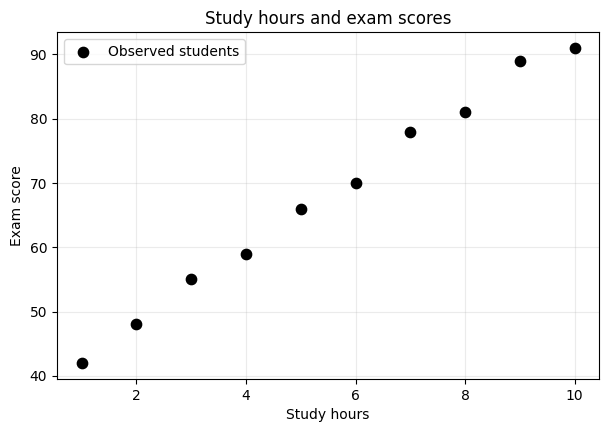

In [22]:
plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color='black', s=55, label='Observed students', zorder=3)
plt.xlabel('Study hours')
plt.ylabel('Exam score')
plt.title('Study hours and exam scores')
plt.grid(alpha=.25)
plt.legend()
plt.show()

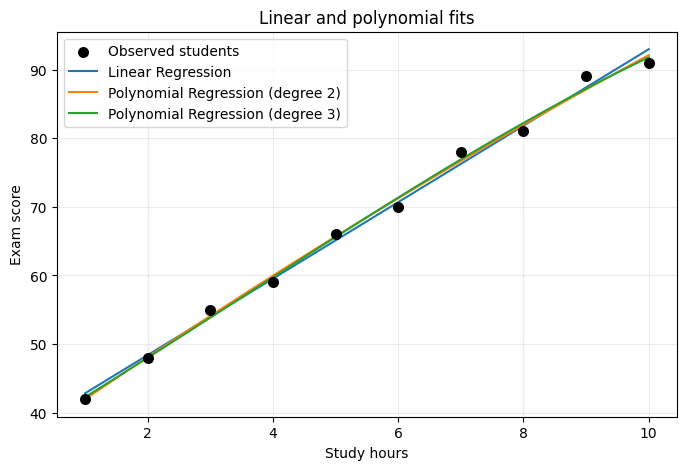

,Training RMSE,Training R²
Model,,
Linear Regression,1.1672,0.9947
Polynomial Regression (degree 2),1.0435,0.9958
Polynomial Regression (degree 3),1.0211,0.9959


In [23]:
models_a = {
    'Linear Regression': Pipeline([('poly', PolynomialFeatures(1, include_bias=False)), ('reg', LinearRegression())]),
    'Polynomial Regression (degree 2)': Pipeline([('poly', PolynomialFeatures(2, include_bias=False)), ('reg', LinearRegression())]),
    'Polynomial Regression (degree 3)': Pipeline([('poly', PolynomialFeatures(3, include_bias=False)), ('reg', LinearRegression())]),
}
xx = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
rows_a = []
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='black', s=48, label='Observed students', zorder=3)
for name, model in models_a.items():
    model.fit(X, y)
    pred = model.predict(X)
    rows_a.append({'Model': name, 'Training RMSE': mean_squared_error(y, pred)**0.5, 'Training R²': r2_score(y, pred)})
    plt.plot(xx, model.predict(xx), label=name)
plt.xlabel('Study hours'); plt.ylabel('Exam score'); plt.title('Linear and polynomial fits')
plt.grid(alpha=.25); plt.legend(); plt.show()
part_a_results = pd.DataFrame(rows_a).set_index('Model')
part_a_results.round(4)

## Part B — Model complexity and generalization

In [24]:
degrees = [1, 2, 3, 5, 9]
complexity_rows = []
for degree in degrees:
    model = Pipeline([('poly', PolynomialFeatures(degree, include_bias=False)), ('reg', LinearRegression())])
    model.fit(X, y)
    train_rmse = mean_squared_error(y, model.predict(X))**0.5
    fold_mse = -cross_val_score(model, X, y, cv=loo, scoring='neg_mean_squared_error')
    complexity_rows.append({'Polynomial Degree': degree, 'Training RMSE': train_rmse, 'LOOCV RMSE': np.sqrt(fold_mse.mean())})
complexity_results = pd.DataFrame(complexity_rows).set_index('Polynomial Degree')
complexity_results.round(4)

,Training RMSE,LOOCV RMSE
Polynomial Degree,,
1,1.1672,1.5486
2,1.0435,1.5728
3,1.0211,2.0620
5,0.8943,3.7070
9,0.0001,261.9061


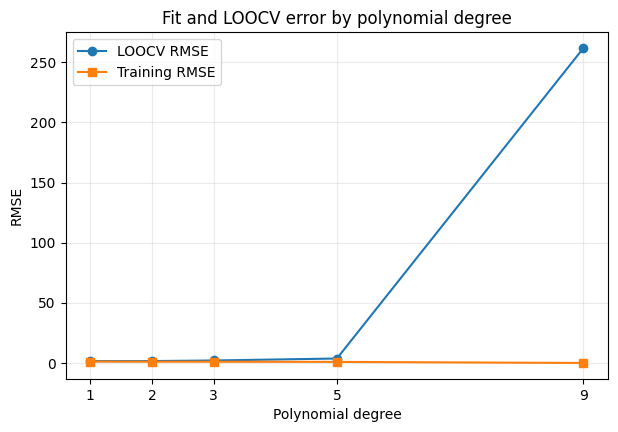

Lowest LOOCV RMSE among the tested polynomial degrees: degree 1 (1.549).


In [25]:
plt.figure(figsize=(7, 4.5))
plt.plot(complexity_results.index, complexity_results['LOOCV RMSE'], marker='o', label='LOOCV RMSE')
plt.plot(complexity_results.index, complexity_results['Training RMSE'], marker='s', label='Training RMSE')
plt.xlabel('Polynomial degree'); plt.ylabel('RMSE'); plt.title('Fit and LOOCV error by polynomial degree')
plt.xticks(degrees); plt.grid(alpha=.25); plt.legend(); plt.show()
best_degree = int(complexity_results['LOOCV RMSE'].idxmin())
print(f"Lowest LOOCV RMSE among the tested polynomial degrees: degree {best_degree} ({complexity_results.loc[best_degree, 'LOOCV RMSE']:.3f}).")

## Part C — Feature representation and regularization

In [26]:
def polynomial_pipeline(degree, estimator):
    return Pipeline([('poly', PolynomialFeatures(degree, include_bias=False)),
                     ('scale', StandardScaler()),
                     ('reg', estimator)])

def loocv_rmse(estimator):
    mse = -cross_val_score(estimator, X, y, cv=loo, scoring='neg_mean_squared_error')
    return float(np.sqrt(mse.mean()))

representations = [
    ('Linear Regression', 1, LinearRegression()),
    ('Polynomial Regression', 3, LinearRegression()),
    ('Polynomial Regression', 5, LinearRegression()),
]
representation_rows = []
for name, degree, reg in representations:
    pipe = polynomial_pipeline(degree, reg)
    representation_rows.append({'Model': name, 'Feature Degree': degree, 'Regularization': 'None', 'LOOCV RMSE': loocv_rmse(pipe)})
representation_results = pd.DataFrame(representation_rows)
representation_results.round(4)

,Model,Feature Degree,Regularization,LOOCV RMSE
0,Linear Regression,1,None,1.5486
1,Polynomial Regression,3,None,2.0620
2,Polynomial Regression,5,None,3.7070


In [17]:
alphas = [0.01, 0.1, 1, 10]
regularization_rows = []
for kind, estimator in [('Ridge (L2)', Ridge), ('Lasso (L1)', Lasso)]:
    for alpha in alphas:
        model = polynomial_pipeline(5, estimator(alpha=alpha, max_iter=100000) if kind.startswith('Lasso') else estimator(alpha=alpha))
        regularization_rows.append({'Model': kind, 'Feature Degree': 5, 'Alpha': alpha, 'LOOCV RMSE': loocv_rmse(model)})
regularization_sweep = pd.DataFrame(regularization_rows)
regularization_sweep.round(4)

,Model,Feature Degree,Alpha,LOOCV RMSE
0,Ridge (L2),5,0.01,2.1442
1,Ridge (L2),5,0.10,1.8071
2,Ridge (L2),5,1.00,3.5735
3,Ridge (L2),5,10.00,7.2820
4,Lasso (L1),5,0.01,1.7654
5,Lasso (L1),5,0.10,1.6223
6,Lasso (L1),5,1.00,1.9187
7,Lasso (L1),5,10.00,11.8773


In [18]:
best_ridge_alpha = float(regularization_sweep.query("Model == 'Ridge (L2)'").sort_values('LOOCV RMSE').iloc[0]['Alpha'])
best_lasso_alpha = float(regularization_sweep.query("Model == 'Lasso (L1)'").sort_values('LOOCV RMSE').iloc[0]['Alpha'])
part_c_rows = representation_rows + [
    {'Model': 'Ridge Regression', 'Feature Degree': 5, 'Regularization': f'L2, alpha={best_ridge_alpha:g}', 'LOOCV RMSE': float(regularization_sweep.query("Model == 'Ridge (L2)'").sort_values('LOOCV RMSE').iloc[0]['LOOCV RMSE'])},
    {'Model': 'Lasso Regression', 'Feature Degree': 5, 'Regularization': f'L1, alpha={best_lasso_alpha:g}', 'LOOCV RMSE': float(regularization_sweep.query("Model == 'Lasso (L1)'").sort_values('LOOCV RMSE').iloc[0]['LOOCV RMSE'])},
]
part_c_results = pd.DataFrame(part_c_rows)
part_c_results.round(4)

,Model,Feature Degree,Regularization,LOOCV RMSE
0,Linear Regression,1,None,1.5486
1,Polynomial Regression,3,None,2.0620
2,Polynomial Regression,5,None,3.7070
3,Ridge Regression,5,"L2, alpha=0.1",1.8071
4,Lasso Regression,5,"L1, alpha=0.1",1.6223


## Part D — Final comparison

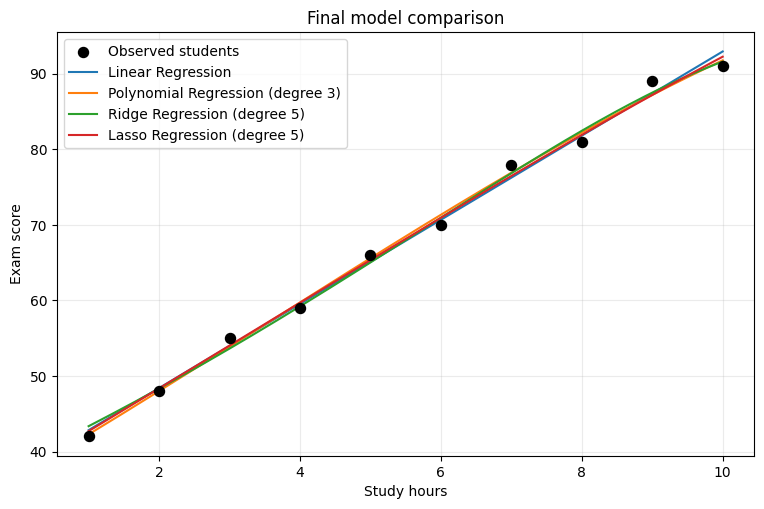

,Training RMSE,LOOCV RMSE
Model,,
Linear Regression,1.1672,1.5486
Polynomial Regression (degree 3),1.0211,2.0620
Ridge Regression (degree 5),1.0865,1.8071
Lasso Regression (degree 5),1.0656,1.6223


In [19]:
final_models = {
    'Linear Regression': polynomial_pipeline(1, LinearRegression()),
    'Polynomial Regression (degree 3)': polynomial_pipeline(3, LinearRegression()),
    'Ridge Regression (degree 5)': polynomial_pipeline(5, Ridge(alpha=best_ridge_alpha)),
    'Lasso Regression (degree 5)': polynomial_pipeline(5, Lasso(alpha=best_lasso_alpha, max_iter=100000)),
}
final_rows = []
plt.figure(figsize=(9, 5.5))
plt.scatter(X, y, color='black', s=52, label='Observed students', zorder=4)
for name, model in final_models.items():
    model.fit(X, y)
    train_rmse = mean_squared_error(y, model.predict(X))**0.5
    cv_rmse = loocv_rmse(model)
    final_rows.append({'Model': name, 'Training RMSE': train_rmse, 'LOOCV RMSE': cv_rmse})
    plt.plot(xx, model.predict(xx), label=name)
plt.xlabel('Study hours'); plt.ylabel('Exam score'); plt.title('Final model comparison')
plt.grid(alpha=.25); plt.legend(); plt.show()
final_results = pd.DataFrame(final_rows).set_index('Model')
final_results.round(4)

## Additional estimator benchmark

In [20]:
extra_models = {
    'Decision Tree (depth 2)': DecisionTreeRegressor(max_depth=2, random_state=42),
    'Random Forest (100 trees)': RandomForestRegressor(n_estimators=100, max_depth=2, random_state=42),
    'SVR (RBF)': Pipeline([('scale', StandardScaler()), ('reg', SVR(C=10, epsilon=2))]),
    'KNN (k=3)': Pipeline([('scale', StandardScaler()), ('reg', KNeighborsRegressor(n_neighbors=3))]),
}
extra_rows = []
for name, model in extra_models.items():
    extra_rows.append({'Model': name, 'LOOCV RMSE': loocv_rmse(model)})
pd.DataFrame(extra_rows).set_index('Model').round(4)

,LOOCV RMSE
Model,
Decision Tree (depth 2),8.9250
Random Forest (100 trees),5.2614
SVR (RBF),8.3405
KNN (k=3),6.1761
